# elapid's Geospatial Features

This notebook reviews common patterns for working with vector and raster data using `elapid`.

We'll review the core tools used for extracting raster data from points and polygons, assigning sample weights based on sample density, and creating spatially-explicit train/test data, while also showing general patterns for working with the `GeoDataFrame` and `GeoSeries` classes from `geopandas`, which are frequently used.

The sample data we'll use includes species occurrence records from the genus *Ariolimax*, a group of North American terrestrial slugs, as well as some climate and vegetation data.

Several datasets used here are hosted on a web server. These files can be accessed locally with `ela.download_sample_data()`, but we'll work with them directly on the web to demonstrate that reading remote data is nearly identical to reading local data thanks to the amazing libraries `elapid` is built on top of.

## Packages, paths & preferences

In [2]:
# packages
import elapid as ela

import os
from pprint import pprint
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
from sklearn import metrics
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.metrics import RocCurveDisplay


In [3]:
## Load the prepared data
plants = gpd.read_file("../data/plants.geojson")
plants['species'].value_counts().head(12)

species
Kalmia angustifolia           1795
Rhododendron canadense         890
Rhododendron groenlandicum     774
Kalmia polifolia               282
Rhododendron maximum            39
Rhododendron lapponicum         36
Kalmia latifolia                20
Rhododendron calendulaceum       3
Rhododendron minus               3
Rhododendron luteum              3
Rhododendron fortunei            3
Rhododendron viscosum            2
Name: count, dtype: int64

In [4]:
polifolia = plants[plants['species']=='Kalmia polifolia']
display(polifolia.head(3))

,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,geometry
1813,6334742478,Kalmia polifolia,-70.475014,43.546137,3.0,2026.0,POINT (-70.47501 43.54614)
1815,6352431553,Kalmia polifolia,-68.319288,44.236267,4.0,2026.0,POINT (-68.31929 44.23627)
1816,6352661134,Kalmia polifolia,-68.724057,44.868975,3.0,2026.0,POINT (-68.72406 44.86898)


In [5]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())

### Reading vector files

Point-format data are most commonly provided in formats like GeoPackage, GeoJSON, or Shapefiles. You can read these into memory easily with `geopandas`.

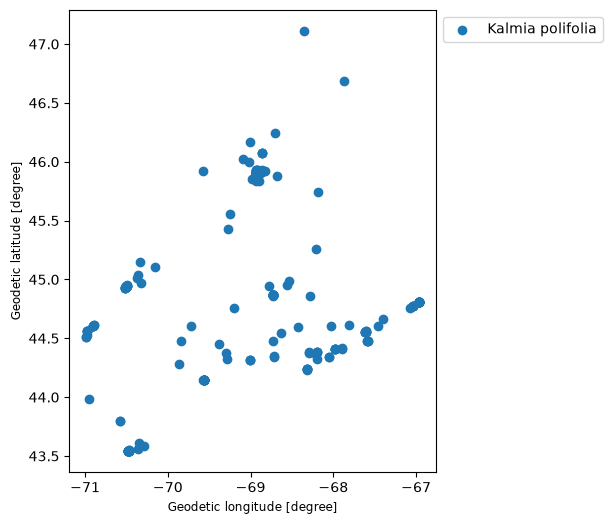

In [6]:
# plot the points geographically by species
fig, ax = plt.subplots(figsize=(6,6))
sp = polifolia.plot(
    column='species',
    ax=ax,
    legend=True,
    legend_kwds={"bbox_to_anchor": (1, 1)}
)

## Working with raster data

This demo includes 6 raster files defined at the start of the notebook, corresponding to the average and standard deviation in annual cloud cover, temperature, and vegetation growth across California.

Following a brief overview of the rasters, the sections below will review how to extract data from them using point and polygon vector data.

c:\Users\Braec\Desktop\BIO597-SpatialBiodiversity\.venv\Lib\site-packages\matplotlib\colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


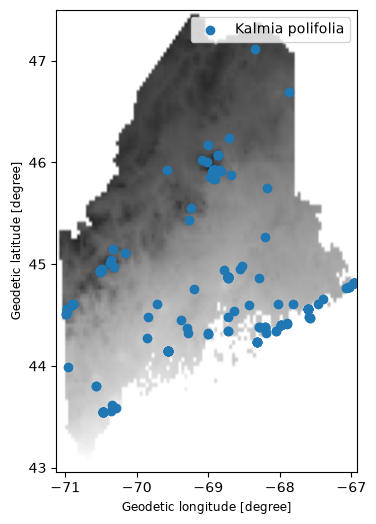

In [7]:
# first we'll just read and display the surface temperature data
fig, ax = plt.subplots(figsize=(6,6))
surfacetemp_raster = rasters[0]
with rio.open(surfacetemp_raster, 'r') as src:
    
    # this plots the mean annual temperature data
    # low temps are dark grey, high temps are light grey
    rioplot.show(src, ax=ax, cmap="gray")
    
    # overlay the ariolimax data
    polifolia.to_crs(src.crs).plot(column='species', ax=ax, legend=True)

## Drawing random pseudoabsence locations

In addition to species occurrence records (where `y = 1`), species distributions models often require a set of random pseudo-absence/background points (`y = 0`). These are a random geographic sampling of where you might expect to find a species across the target landscape.

The background point distribution is extremely important for presence-only models, and should be selected with care. `elapid` provides a range of methods for sample selection.

For the unintiated, these papers by [Morgane Barbet-Massin et al.](https://besjournals.onlinelibrary.wiley.com/doi/10.1111/j.2041-210X.2011.00172.x) and [Phillips et al.](https://esajournals.onlinelibrary.wiley.com/doi/abs/10.1890/07-2153.1) are excellent resources to consult for considering how background point samples should be selected.

### From a raster's extent

You can use `elapid` to create a uniform random geographic sample from unmasked locations within a raster's extent:

count                                   1000
unique                                   912
top       POINT (-70.97916666666667 44.3125)
freq                                       3
dtype: object

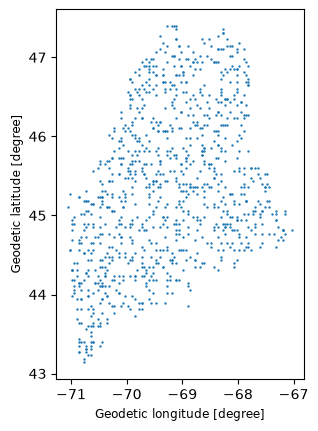

In [8]:
# sampling
count = 1000
pseudoabsence = ela.sample_raster(surfacetemp_raster, count)

# plotting
pseudoabsence.plot(markersize=0.5)
pseudoabsence.describe()

In [9]:
# some pixel centroids were sampled multiple times
# you can drop them if you'd like.
pseudoabsence.drop_duplicates(inplace=True)
pseudoabsence.describe()

C:\Users\Braec\AppData\Local\Temp\ipykernel_27348\822005418.py:3: Pandas4Warning: The inplace keyword in GeoSeries.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pseudoabsence.drop_duplicates(inplace=True)


count                                    912
unique                                   912
top       POINT (-70.02083333333333 46.0625)
freq                                       1
dtype: object

### From a bias raster

You could also provide a "bias" file to the [ela.sample_bias_file()](https://earth-chris.github.io/elapid/module/geo/#elapid.geo.sample_bias_file) function, where the raster grid cells contain information on the probability of sampling an area. Bias adjustments are recommended because species occurrence records are often biased towards certain locations (near roads, parks, or trails).

The grid cells can be an arbitrary range of values. What's important is that the values encode a linear range of numbers that are higher where you're more likely to draw a sample. The probability of drawing a sample is dependent on two factors: the range of values provided and the frequency of values across the dataset.

Because amphibians are ectotherms, we'll guess that people are more likely to look for them in warmer areas (in Maine). We'll use the mean annual temperature covariate to select more background samples from warmer areas.

count                                              1000
unique                                              905
top       POINT (-69.52083333333333 44.229166666666664)
freq                                                  3
dtype: object

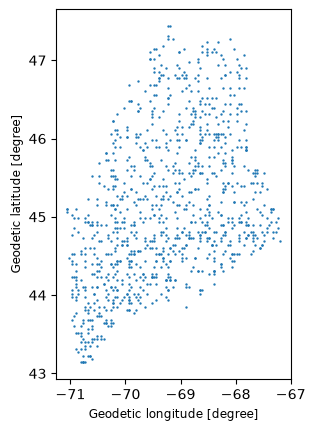

In [10]:
mean_temp_raster = rasters[0]
pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count)
pseudoabsence_bias.plot(markersize=0.5)
pseudoabsence_bias.describe()

In [11]:
# again, duplicates can be dropped
# (this can take some time to run)
pseudoabsence_bias.drop_duplicates(inplace=True)
pseudoabsence_bias.describe()

C:\Users\Braec\AppData\Local\Temp\ipykernel_27348\2825892058.py:3: Pandas4Warning: The inplace keyword in GeoSeries.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  pseudoabsence_bias.drop_duplicates(inplace=True)


count                                    905
unique                                   905
top       POINT (-70.35416666666667 44.0625)
freq                                       1
dtype: object

We can see that we are selecting a disproportionately high number of points in the south and disproportionately few samples in the colder north.

## Point annotation

Annotation refers to extracting raster values at the each point occurrence record and storing those records together in a `GeoDataFrame`. Once you have your presence and pseudo-absence records, you can annotate these records with the corresponding covariate data.

This function, since it's geographically indexed, doesn't require the point data and the raster data to be in the same projection. `elapid` handles reprojection and resampling on the fly.

It also allows you to pass multiple raster files, which can be in different projections, extents, or grid sizes. This means you don't have to explicitly re-sample your raster data prior to analysis, which is always a chore.

In [12]:
presence = ela.annotate(
    polifolia.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

# we'll use the biased sample locations
background = ela.annotate(
    pseudoabsence_bias,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

Setting `drop_na=True` works with raster datasets that have nodata values assigned in their metadata. These point locations will be dropped from the output dataframe.

Next let's plot some histograms to understand the similarities and differences between the conditions at presence locations and at background locations.

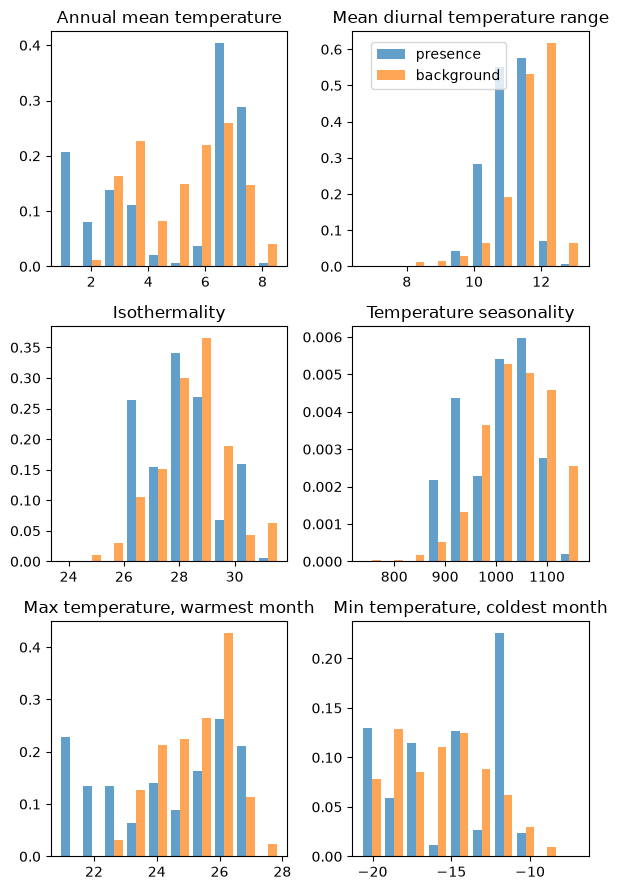

In [13]:
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6,9))

for label, ax in zip(labels, axs.ravel()):
    pvar = presence[label]
    bvar = background[label]
    ax.hist(
        [pvar, bvar],
        density=True,
        alpha=0.7,
        label=['presence', 'background'],
    )
    ax.set_title(label)
    
handles, lbls = ax.get_legend_handles_labels()
fig.legend(handles, lbls, loc=(0.6, 0.9))
plt.tight_layout()

This checks out. Lithobes are commonly found in areas with higher mean annual temperature, and lower temperature seasonality (even after adjusting for bias and oversampling areas with high mean annual temperature).

## Geographic sample weights

Despite ingesting spatial data, many statistically-driven SDMs are not spatial models in a traditional sense: they don't handle geographic information during model selection or in model scoring.

One way to add spatial information to a model is to compute geographically-explicit sample weights. `elapid` does this by calculating weights based on the distance to the nearest neighbor. Points nearby other points receive lower weight scores; far-away points receive higher weight scores.

You can compute weights based on the distance to the nearest point by setting `n_neighbors=1`.


c:\Users\Braec\Desktop\BIO597-SpatialBiodiversity\.venv\Lib\site-packages\elapid\geo.py:921: UserWarning: Computing distances using geographic coordinates is bad
  distances = nearest_point_distance(points, n_neighbors=n_neighbors, cpu_count=cpu_count)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

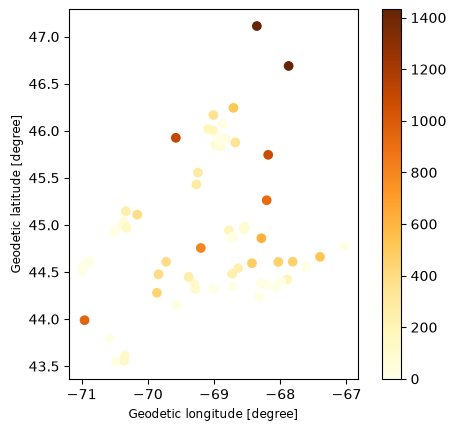

In [14]:
presence['SampleWeight'] = ela.distance_weights(presence, n_neighbors=1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

The warning here is telling us something important, namely that it is not good
to calculate distance using decimal Lat/Long values (i.e. `EPSG:4326`)
We will use [`EPSG:26919`](https://epsg.io/32619), UTM Zone 19N, for Maine, which is a projected coordinate system with units in meters.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

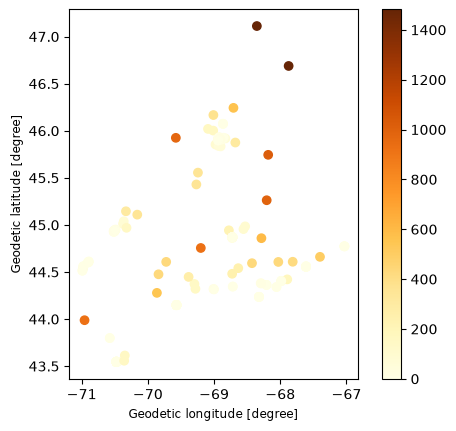

In [15]:
presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

Alternatively, you could compute the average distance from each point to all other points, computing sample weights from point density instead of the distance to the single nearest point. This may be useful if you have small clusters of a few points far away from large, densely populated regions, like the above.

This is the default parameter setting (and specified by setting `n_neighbors=-1`).

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

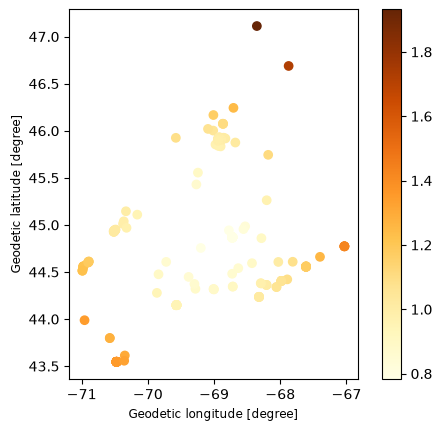

In [16]:
background['SampleWeight'] = ela.distance_weights(background.to_crs('EPSG:26919'), n_neighbors=-1)
presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=-1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

As you can see, there are tradeoffs for finding the best sample weights depending on the spatial distributions of each occurrence dataset. We'll use the sample density weights here to upweight the samples in the northeastern and southwestern regions.

## Stacking dataframes

Now that we have our presence points and our pseudoabsence points, we can merge them together into a single dataset for analysis.

`elapid` provides a convenience function for merging GeoDataFrames, designed for stacking presence/background data. It will reproject geometries on the fly if needed, and you can optionally add a 'class' column to the output GeoDataFrame.

In [17]:
merged = ela.stack_geodataframes(
    presence,
    background,
    add_class_label=True,
).to_crs('EPSG:26919')
merged.head()

,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter",...,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry,SampleWeight,class
0,7.538500,11.530334,30.282417,945.079285,26.416000,-11.660000,38.076000,3.252000,18.290001,19.026667,...,125.0,82.0,13.652273,340.0,249.0,253.0,287.0,POINT (380843.633 4822522.082),1.357543,1
1,7.106250,9.727777,27.596533,895.186279,24.600000,-10.650000,35.250000,-1.352778,17.916666,17.916666,...,150.0,74.0,18.928030,409.0,254.0,254.0,360.0,POINT (554358.477 4898340.312),1.022219,1
2,6.577000,11.640667,28.702698,1016.534180,26.696001,-13.860000,40.556000,1.968667,-5.145333,18.863335,...,101.0,70.0,8.957572,290.0,237.0,266.0,254.0,POINT (521798.04 4968432.383),0.784052,1
3,6.577000,11.640667,28.702698,1016.534180,26.696001,-13.860000,40.556000,1.968667,-5.145333,18.863335,...,101.0,70.0,8.957572,290.0,237.0,266.0,254.0,POINT (521812.868 4968601.84),0.784139,1
4,6.956127,10.049510,27.684601,919.785645,24.923529,-11.376471,36.299999,-1.769608,18.040195,18.040195,...,153.0,75.0,19.037455,421.0,260.0,260.0,374.0,POINT (563092.581 4912476.9),1.004693,1


## Model setup

We won't get into much detail on model parameters, leaving that for another in-depth notebook. This section will focus on fitting models using default settings, then evaluate the effects of different forms of train/test splitting strategies.

In [ ]:
# initialize and print the model defaults
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)
pprint(maxent.get_params())

Unweighted naive AUC score: 0.951
Weighted naive AUC score  : 0.951


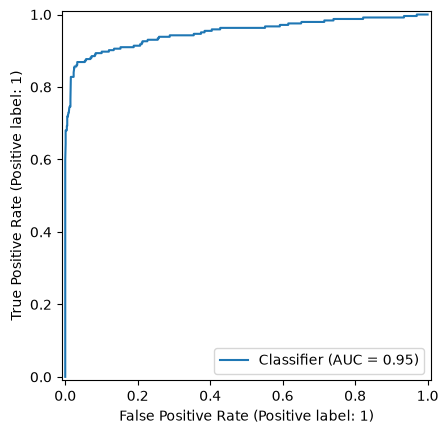

In [19]:
# set up the x/y data for model fitting
X = merged.drop(columns=['class', 'SampleWeight'])
y = merged['class']
sample_weight = merged['SampleWeight']

# fit and evaluate the model under naive conditions
maxent.fit(X, y, sample_weight=sample_weight)
ypred = maxent.predict(X)

print(f"Unweighted naive AUC score: {metrics.roc_auc_score(y, ypred):0.3f}")
RocCurveDisplay.from_predictions(y, ypred)
print(f"Weighted naive AUC score  : {metrics.roc_auc_score(y, ypred, sample_weight=sample_weight):0.3f}")

## Train / test splits

Uniformly random train/test splits are generally discouraged in spatial modeling because of the strong spatial structure inherent in many datasets. The non-independence of these data is referred to as spatial autocorrelation. Using distance- or density-based sample weights is one way to mitigate these effects. Another is to split the data into geographically distinct train/test regions to try and prioritize model generalization.

### Checkerboard splits

With a "checkerbox" train/test split, points are intersected along a regular grid, and every other grid is used to split the data into train/test sets.

The height and width of the grid used to split the data is controlled by the `grid_size` parameter. This should specify distance in the units of the point data's CRS. In our example, the units are in *meters*.

The black and white structure of the checkerboard means this method can only generate one train/test split.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

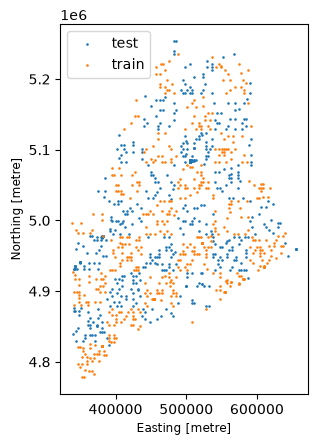

In [20]:
# let's use a 50km grid
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)

# we'll re-merge them for plotting purposes
train['split'] = 'train'
test['split'] = 'test'
checker = ela.stack_geodataframes(train, test)
checker.plot(column='split', markersize=0.75, legend=True)

In [21]:
# set up model fitting
Xtrain = train.drop(columns=['class', 'SampleWeight', 'split'])
ytrain = train['class']
sample_weight_train = train['SampleWeight']

Xtest = test.drop(columns=['class', 'SampleWeight', 'split'])
ytest = test['class']
sample_weight_test = test['SampleWeight']

maxent.fit(Xtrain, ytrain, sample_weight=sample_weight_train)
ypred = maxent.predict(Xtest)

print(f"Unweighted checkerboard AUC score: {metrics.roc_auc_score(ytest, ypred):0.3f}")
print(f"Weighted checkerboard AUC score: {metrics.roc_auc_score(ytest, ypred, sample_weight=sample_weight_test):0.3f}")

Unweighted checkerboard AUC score: 0.319
Weighted checkerboard AUC score: 0.320


This lower AUC score is to be expected and should be interpreted as a good thing. It indicates that the naive model was overfitting to nearby points, and the inflated scores were likely the result of spatial autocorrelation.

## Apply the trained model to the ME clipped rasters

In [23]:
output_raster = "polifolia-maxent-predictions.tif"
ela.apply_model_to_rasters(maxent, rasters, output_raster, quiet=True)

# and read into memory
with rio.open(output_raster, 'r') as src:
    pred = src.read(1, masked=True)

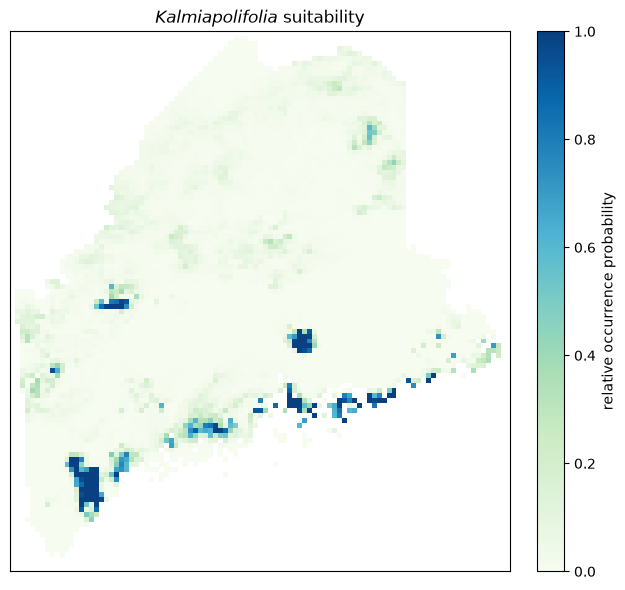

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6), dpi=100)
plot = ax.imshow(pred, vmin=0, vmax=1, cmap='GnBu')
ax.set_title('$Kalmia polifolia$ suitability')
ax.set_xticks([])
ax.set_yticks([])
cbar = plt.colorbar(plot, ax=ax, label="relative occurrence probability", pad=0.04)
plt.tight_layout()

### Buffered leave-one-out

Leave-one-out cross-validation refers to training on *n-1* points and testing on a single test point, looping over the full dataset to test on each point separately.

The buffered leave-one-out strategy, as described by [Ploton et al.](https://www.nature.com/articles/s41467-020-18321-y), modifies this approach. While each point is iterated over for testing, the pool of available training points is reduced at each iteration by dropping training points located within a certain distance of the test data. The purpose of this method is to evaluate how a model performs far away from where it was trained.

In SDM contexts, however, standard leave-one-out strategies may not be appropriate. Model performance is best evaluated on presence-only data; model performance on background points may not be meaningful.

To only run the leave-one-out analysis on presence-only points, specify the column with the 0/1 class labels during train/test splitting:

In [26]:
# store the individual sample predictions and evaluate at the end
yobs_scores = []
ypred_scores = []

# buffered leave-one-out, 5km buffer radius
distance = 50_000

# Downsample the merged presence/absence data to 500 random rows because LOO is slow
merged_subset = merged.sample(500)

bloo = ela.BufferedLeaveOneOut(distance=distance)
idx = 0
for train_idx, test_idx in bloo.split(merged_subset, class_label="class"):
    idx += 1
    if not idx % 10:
        print(idx, end=" ")
    train = merged_subset.iloc[train_idx]
    test = merged_subset.iloc[test_idx]
    
    # set up model fitting
    xtrain = train.drop(columns=['class'])
    ytrain = train['class']
    xtest = test.drop(columns=['class'])
    ytest = test['class']

    # evaluation
    maxent.fit(xtrain, ytrain)
    ypred = maxent.predict(xtest)
    ypred_scores.append(ypred)
    yobs_scores.append(ytest)

10 20 30 40 50 60 70 80 90 

Buffered leave-one-out AUC: 0.598
Naive model AUC: 0.954


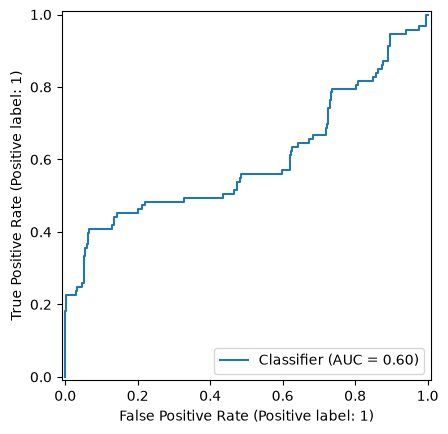

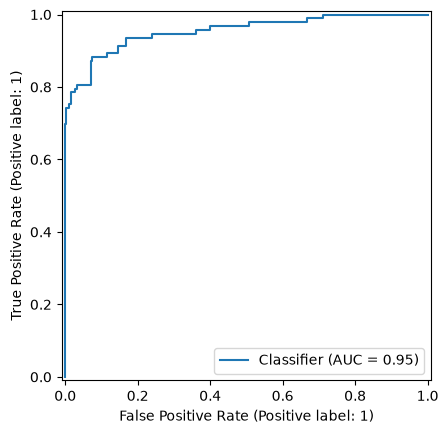

In [27]:
# get model predictions for just the background
bg = merged_subset[merged_subset['class'] == 0]
xbg = bg.drop(columns='class')
ybg = bg['class'].to_numpy()
bg_pred = maxent.predict(xbg)

# concatenate the background and leave-one-out points
bl_pred = np.array(ypred_scores)
bl_obs = np.array(yobs_scores)
ypred = np.vstack((bg_pred.reshape(-1,1), bl_pred))
yobs = np.vstack((ybg.reshape(-1,1), bl_obs))

# evaluate
auc = metrics.roc_auc_score(yobs, ypred)
print(f"Buffered leave-one-out AUC: {auc:0.3f}")
RocCurveDisplay.from_predictions(yobs, ypred)

# no buffer
x = merged_subset.drop(columns=['class'])
y = merged_subset['class']
maxent.fit(x, y)
ypred = maxent.predict(x)
auc = metrics.roc_auc_score(y, ypred)
print(f"Naive model AUC: {auc:0.3f}")
RocCurveDisplay.from_predictions(y, ypred)

array([2.68138684e-04, 1.53044505e-02, 1.00000000e+00, 5.70811108e-02,
       4.61064333e-02, 7.35659321e-02, 1.00000000e+00, 2.56708757e-01,
       3.67728283e-02, 2.61979321e-01, 3.35158360e-02, 1.21283858e-02,
       2.18933359e-04, 9.15569312e-04, 6.41869338e-01, 1.00000000e+00,
       1.97694536e-02, 3.02780834e-02, 6.82790928e-01, 2.81635132e-03,
       1.00000000e+00, 1.29959558e-04, 1.97841235e-04, 1.99560195e-01,
       1.56838608e-02, 6.85588342e-04, 2.81998270e-01, 1.66833707e-02,
       1.44508902e-03, 2.10266091e-02, 2.14601222e-02, 9.70510230e-01,
       1.00000000e+00, 5.79548057e-03, 1.24895013e-01, 7.59572665e-03,
       4.65421626e-02, 9.62437489e-01, 1.00000000e+00, 3.00401537e-03,
       6.91873372e-04, 1.00000000e+00, 2.45025972e-02, 3.85801691e-03,
       8.49089745e-02, 5.11907665e-04, 1.00000000e+00, 8.46149572e-03,
       9.19515954e-04, 2.23001712e-02, 3.43197276e-02, 2.73377758e-04,
       9.17713526e-04, 9.05747544e-03, 2.54240100e-04, 1.00000000e+00,
      

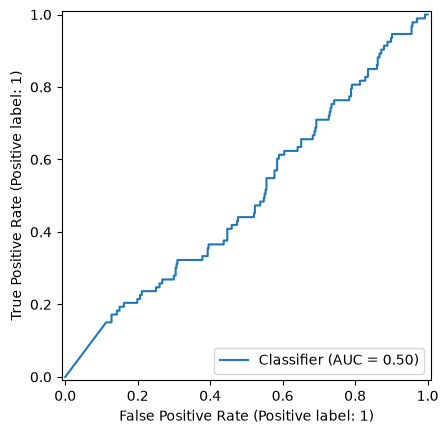

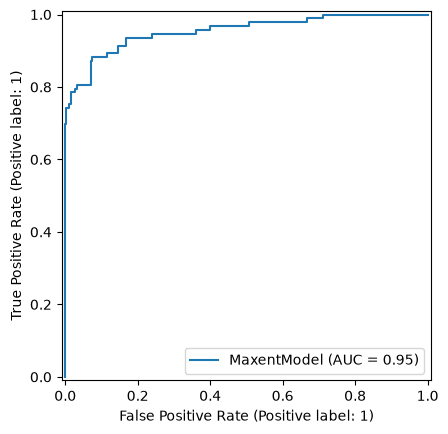

In [29]:

RocCurveDisplay.from_predictions(yobs, ypred)
RocCurveDisplay.from_estimator(maxent, x, y)
ypred